In [1]:

import kagglehub

# Download latest version
path = kagglehub.dataset_download("sohaannn/comprehensive-lemon-leaf-disease-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/sohaannn/comprehensive-lemon-leaf-disease-dataset


In [2]:
import cv2
import shutil
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

# =====================================================
# Configuration
# =====================================================

INPUT_DIR = Path(
    "/kaggle/input/datasets/sohaannn/comprehensive-lemon-leaf-disease-dataset/Original Dataset"
)

OUTPUT_DIR = Path(
    "/kaggle/working/papaya_leaf_preprocessed"
)

IMG_SIZE = 224

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

# Clear old output
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =====================================================
# Image functions
# =====================================================

def read_rgb(path):
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def resize_image(image):
    return cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )


def mild_denoise(image):
    """
    Removes mild image noise while preserving lesion edges.
    """
    return cv2.bilateralFilter(
        image,
        d=5,
        sigmaColor=20,
        sigmaSpace=20
    )


def apply_clahe(image):
    """
    Apply CLAHE only to luminance.
    This improves contrast without strongly changing leaf colors.
    """

    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge([
        enhanced_l,
        a_channel,
        b_channel
    ])

    return cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )


def mild_unsharp_mask(image):
    """
    Restore important leaf veins, lesion borders,
    and disease texture after denoising.
    """

    blurred = cv2.GaussianBlur(
        image,
        (0, 0),
        sigmaX=1.0
    )

    sharpened = cv2.addWeighted(
        image,
        1.25,
        blurred,
        -0.25,
        0
    )

    return np.clip(
        sharpened,
        0,
        255
    ).astype(np.uint8)


def preprocess_leaf(image):
    image = resize_image(image)
    image = mild_denoise(image)
    image = apply_clahe(image)
    image = mild_unsharp_mask(image)

    return image


def save_rgb(path, image):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    image_bgr = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2BGR
    )

    success = cv2.imwrite(
        str(path),
        image_bgr,
        [cv2.IMWRITE_PNG_COMPRESSION, 3]
    )

    if not success:
        raise ValueError(f"Cannot save image: {path}")


# =====================================================
# Process all classes
# =====================================================

records = []
errors = []

class_folders = sorted([
    folder for folder in INPUT_DIR.iterdir()
    if folder.is_dir()
])

for class_folder in class_folders:

    output_class_folder = (
        OUTPUT_DIR / class_folder.name
    )

    output_class_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    image_paths = sorted([
        path
        for path in class_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])

    for image_path in tqdm(
        image_paths,
        desc=class_folder.name
    ):
        try:
            original = read_rgb(image_path)
            processed = preprocess_leaf(original)

            output_path = (
                output_class_folder
                / f"{image_path.stem}.png"
            )

            save_rgb(
                output_path,
                processed
            )

            records.append({
                "class": class_folder.name,
                "input_path": image_path,
                "output_path": output_path
            })

        except Exception as error:
            errors.append({
                "path": str(image_path),
                "error": str(error)
            })


# =====================================================
# Print processed image counts
# =====================================================

print("\nPreprocessed tomato leaf image counts")
print("=" * 75)

overall_total = 0

for class_folder in class_folders:

    output_class_folder = (
        OUTPUT_DIR / class_folder.name
    )

    count = sum(
        1
        for path in output_class_folder.iterdir()
        if path.suffix.lower() in IMAGE_EXTENSIONS
    )

    overall_total += count

    print(
        f"{class_folder.name:50s}: "
        f"{count:5d} images"
    )

print("-" * 75)
print(f"Number of classes : {len(class_folders)}")
print(f"Total images      : {overall_total}")
print(f"Processing errors : {len(errors)}")
print(f"Saved directory   : {OUTPUT_DIR}")

Anthracnose:   0%|          | 0/100 [00:00<?, ?it/s]

Bacterial Blight:   0%|          | 0/105 [00:00<?, ?it/s]

Citrus Canker:   0%|          | 0/178 [00:00<?, ?it/s]

Curl Virus:   0%|          | 0/115 [00:00<?, ?it/s]

Deficiency Leaf:   0%|          | 0/193 [00:00<?, ?it/s]

Dry Leaf:   0%|          | 0/186 [00:00<?, ?it/s]

Healthy Leaf:   0%|          | 0/210 [00:00<?, ?it/s]

Sooty Mould:   0%|          | 0/153 [00:00<?, ?it/s]

Spider Mites:   0%|          | 0/114 [00:00<?, ?it/s]


Preprocessed tomato leaf image counts
Anthracnose                                       :   100 images
Bacterial Blight                                  :   105 images
Citrus Canker                                     :   178 images
Curl Virus                                        :   115 images
Deficiency Leaf                                   :   193 images
Dry Leaf                                          :   186 images
Healthy Leaf                                      :   210 images
Sooty Mould                                       :   153 images
Spider Mites                                      :   114 images
---------------------------------------------------------------------------
Number of classes : 9
Total images      : 1354
Processing errors : 0
Saved directory   : /kaggle/working/papaya_leaf_preprocessed


In [3]:
import random
import shutil
from pathlib import Path

# =====================================================
# Configuration
# =====================================================

SEED = 42
random.seed(SEED)

SOURCE_DIR = Path(
    "/kaggle/working/papaya_leaf_preprocessed"
)

SPLIT_DIR = Path(
    "/kaggle/working/papaya_leaf_split"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

# Remove previous split directory
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# Split each class separately
# =====================================================

split_counts = {}

class_folders = sorted([
    folder
    for folder in SOURCE_DIR.iterdir()
    if folder.is_dir()
])

for class_folder in class_folders:

    images = sorted([
        path
        for path in class_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])

    random.shuffle(images)

    total = len(images)

    train_count = int(total * 0.80)
    validation_count = int(total * 0.10)

    train_images = images[:train_count]

    validation_images = images[
        train_count:
        train_count + validation_count
    ]

    test_images = images[
        train_count + validation_count:
    ]

    splits = {
        "train": train_images,
        "validation": validation_images,
        "test": test_images
    }

    for split_name, split_images in splits.items():

        output_folder = (
            SPLIT_DIR
            / split_name
            / class_folder.name
        )

        output_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        for image_path in split_images:
            shutil.copy2(
                image_path,
                output_folder / image_path.name
            )

        split_counts[
            (split_name, class_folder.name)
        ] = len(split_images)

print(f"Split dataset saved in:\n{SPLIT_DIR}")

Split dataset saved in:
/kaggle/working/papaya_leaf_split


In [4]:
import random
import shutil
from pathlib import Path

from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# =====================================================
# Configuration
# =====================================================

SEED = 42
random.seed(SEED)

TRAIN_DIR = Path(
    "/kaggle/working/papaya_leaf_split/train"
)

AUGMENTED_DIR = Path(
    "/kaggle/working/papaya_leaf_train_augmented"
)

AUGMENTATIONS_PER_IMAGE = 2

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

# Remove previous augmented folder
if AUGMENTED_DIR.exists():
    shutil.rmtree(AUGMENTED_DIR)

AUGMENTED_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# Tomato-leaf-safe augmentation
# =====================================================

augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=25,
        interpolation=InterpolationMode.BICUBIC,
        fill=255
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.90, 1.10),
        shear=5,
        interpolation=InterpolationMode.BICUBIC,
        fill=255
    ),

    transforms.RandomPerspective(
        distortion_scale=0.10,
        p=0.30,
        interpolation=InterpolationMode.BICUBIC,
        fill=255
    ),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.10,
        hue=0.02
    )
])

# =====================================================
# Original + two augmented images
# =====================================================

class_counts = {}

class_folders = sorted([
    folder
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

for class_folder in class_folders:

    output_folder = AUGMENTED_DIR / class_folder.name
    output_folder.mkdir(parents=True, exist_ok=True)

    image_paths = sorted([
        path
        for path in class_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])

    original_count = 0
    augmented_count = 0
    error_count = 0

    for image_path in tqdm(
        image_paths,
        desc=class_folder.name
    ):
        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")

                # Save original
                original_path = (
                    output_folder
                    / f"{image_path.stem}_original.png"
                )

                image.save(original_path)
                original_count += 1

                # Generate two augmented versions
                for aug_number in range(
                    1,
                    AUGMENTATIONS_PER_IMAGE + 1
                ):
                    augmented_image = augmentation(image)

                    augmented_path = (
                        output_folder
                        / f"{image_path.stem}_aug{aug_number}.png"
                    )

                    augmented_image.save(augmented_path)
                    augmented_count += 1

        except Exception as error:
            error_count += 1
            print(f"Skipped {image_path}: {error}")

    class_counts[class_folder.name] = {
        "original": original_count,
        "augmented": augmented_count,
        "total": original_count + augmented_count,
        "errors": error_count
    }

# =====================================================
# Print class-wise counts
# =====================================================

print("\nAugmented tomato training dataset")
print("=" * 100)

overall_original = 0
overall_augmented = 0
overall_total = 0
overall_errors = 0

for class_name, counts in class_counts.items():

    overall_original += counts["original"]
    overall_augmented += counts["augmented"]
    overall_total += counts["total"]
    overall_errors += counts["errors"]

    print(
        f"{class_name:55s} | "
        f"Original: {counts['original']:4d} | "
        f"Augmented: {counts['augmented']:4d} | "
        f"Total: {counts['total']:4d}"
    )

print("-" * 100)
print(f"Original training images : {overall_original}")
print(f"Generated augmentations  : {overall_augmented}")
print(f"Final training images     : {overall_total}")
print(f"Processing errors         : {overall_errors}")
print(f"Saved directory           : {AUGMENTED_DIR}")

Anthracnose:   0%|          | 0/80 [00:00<?, ?it/s]

Bacterial Blight:   0%|          | 0/84 [00:00<?, ?it/s]

Citrus Canker:   0%|          | 0/142 [00:00<?, ?it/s]

Curl Virus:   0%|          | 0/92 [00:00<?, ?it/s]

Deficiency Leaf:   0%|          | 0/154 [00:00<?, ?it/s]

Dry Leaf:   0%|          | 0/148 [00:00<?, ?it/s]

Healthy Leaf:   0%|          | 0/168 [00:00<?, ?it/s]

Sooty Mould:   0%|          | 0/122 [00:00<?, ?it/s]

Spider Mites:   0%|          | 0/91 [00:00<?, ?it/s]


Augmented tomato training dataset
Anthracnose                                             | Original:   80 | Augmented:  160 | Total:  240
Bacterial Blight                                        | Original:   84 | Augmented:  168 | Total:  252
Citrus Canker                                           | Original:  142 | Augmented:  284 | Total:  426
Curl Virus                                              | Original:   92 | Augmented:  184 | Total:  276
Deficiency Leaf                                         | Original:  154 | Augmented:  308 | Total:  462
Dry Leaf                                                | Original:  148 | Augmented:  296 | Total:  444
Healthy Leaf                                            | Original:  168 | Augmented:  336 | Total:  504
Sooty Mould                                             | Original:  122 | Augmented:  244 | Total:  366
Spider Mites                                            | Original:   91 | Augmented:  182 | Total:  273
--------------------

SHUFFLENET V2

Downloading: "https://download.pytorch.org/models/shufflenetv2_x1-5666bf0f80.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x1-5666bf0f80.pth
Model: shufflenet_v2_x1_0
Best Validation Accuracy: 98.48%
Test Accuracy: 95.74%
Confusion Matrix:
[[10  0  0  0  0  0  0  0  0]
 [ 0 10  0  0  0  0  0  1  0]
 [ 0  0 19  0  0  0  0  0  0]
 [ 1  0  0 11  0  0  0  0  0]
 [ 0  0  0  0 20  0  0  0  0]
 [ 0  0  0  0  0 20  0  0  0]
 [ 0  0  0  0  0  0 21  0  0]
 [ 0  3  0  0  0  0  1 12  0]
 [ 0  0  0  0  0  0  0  0 12]]


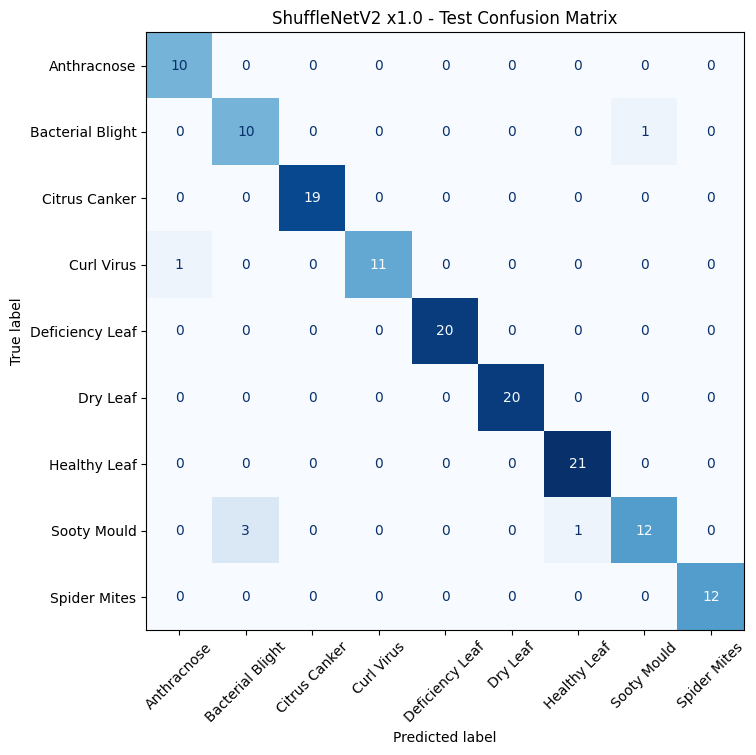

In [ ]:
import os
import gc
import math
import random
import warnings
import logging
from pathlib import Path
from contextlib import nullcontext

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"

warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import InterpolationMode


from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# ============================================================
# Configuration
# ============================================================

TRAIN_PATH = Path("/kaggle/working/papaya_leaf_train_augmented")
VAL_PATH = Path("/kaggle/working/papaya_leaf_split/validation")
TEST_PATH = Path("/kaggle/working/papaya_leaf_split/test")

OUTPUT_DIR = Path("/kaggle/working/papaya_shufflenetv2_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, CHECKPOINT_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "shufflenet_v2_x1_0"
MODEL_SAVE_PATH = CHECKPOINT_DIR / "best_shufflenetv2_x1_0.pth"

INPUT_SIZE = 224
EPOCHS = 30
PATIENCE = 5

BATCH_SIZE = 16
BACKBONE_LR = 3e-5
HEAD_LR = 2e-4
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.30

LABEL_SMOOTHING = 0.05
FOCAL_GAMMA = 1.5
WARMUP_EPOCHS = 3
USE_CLASS_WEIGHTS = True

SEED = 42
NUM_WORKERS = min(4, os.cpu_count() or 2)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"


# ============================================================
# Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


seed_everything(SEED)


# ============================================================
# Dataset checks
# ============================================================

for path in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Dataset path does not exist: {path}")

train_reference = datasets.ImageFolder(TRAIN_PATH)
val_reference = datasets.ImageFolder(VAL_PATH)
test_reference = datasets.ImageFolder(TEST_PATH)

CLASS_NAMES = train_reference.classes
NUM_CLASSES = len(CLASS_NAMES)

if NUM_CLASSES < 2:
    raise ValueError("At least two training classes are required.")

if val_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Validation classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nValidation: {val_reference.classes}"
    )

if test_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Test classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nTest: {test_reference.classes}"
    )

del train_reference, val_reference, test_reference


# ============================================================
# Pretrained CNN creation and classifier replacement
# ============================================================

def create_pretrained_model():
    try:
        weights = models.ShuffleNet_V2_X1_0_Weights.DEFAULT
        current_model = models.shufflenet_v2_x1_0(
            weights=weights,
            progress=False,
        )
    except AttributeError:
        current_model = models.shufflenet_v2_x1_0(
            pretrained=True,
            progress=False,
        )

    in_features = current_model.fc.in_features
    current_model.fc = nn.Sequential(
        nn.Dropout(p=DROPOUT_RATE),
        nn.Linear(in_features, NUM_CLASSES),
    )

    return current_model, current_model.fc


model, head_module = create_pretrained_model()
model = model.to(DEVICE)


# ============================================================
# ImageNet normalization and transforms
# ============================================================

MODEL_MEAN = (0.485, 0.456, 0.406)
MODEL_STD = (0.229, 0.224, 0.225)
INTERPOLATION = InterpolationMode.BILINEAR

train_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=8,
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])

evaluation_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])


# ============================================================
# Datasets and loaders
# ============================================================

train_dataset = datasets.ImageFolder(
    TRAIN_PATH,
    transform=train_transform,
)

val_dataset = datasets.ImageFolder(
    VAL_PATH,
    transform=evaluation_transform,
)

test_dataset = datasets.ImageFolder(
    TEST_PATH,
    transform=evaluation_transform,
)

if train_dataset.class_to_idx != val_dataset.class_to_idx:
    raise ValueError("Train and validation class mappings are different.")

if train_dataset.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test class mappings are different.")

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": AMP_ENABLED,
    "persistent_workers": NUM_WORKERS > 0,
    "worker_init_fn": seed_worker,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=False,
    generator=loader_generator,
    **loader_common,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)


# ============================================================
# Class weights
# ============================================================

def get_class_weights(dataset):
    if not USE_CLASS_WEIGHTS:
        return None

    counts = np.bincount(
        dataset.targets,
        minlength=NUM_CLASSES,
    ).astype(np.float32)

    if np.any(counts == 0):
        raise ValueError(f"Empty class detected. Counts: {counts.tolist()}")

    weights = len(dataset) / (NUM_CLASSES * counts)
    weights = weights / weights.mean()

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=DEVICE,
    )


class_weights = get_class_weights(train_dataset)


# ============================================================
# Focal loss with label smoothing
# ============================================================

class FocalLoss(nn.Module):
    def __init__(
        self,
        gamma=1.5,
        label_smoothing=0.05,
        weight=None,
    ):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing

        if weight is None:
            self.register_buffer("weight", None)
        else:
            self.register_buffer("weight", weight)

    def forward(self, logits, targets):
        cross_entropy = F.cross_entropy(
            logits,
            targets,
            weight=self.weight,
            label_smoothing=self.label_smoothing,
            reduction="none",
        )

        target_probability = F.softmax(
            logits,
            dim=1,
        ).gather(
            1,
            targets.unsqueeze(1),
        ).squeeze(1)

        focal_factor = (1.0 - target_probability).pow(self.gamma)
        return (focal_factor * cross_entropy).mean()


criterion = FocalLoss(
    gamma=FOCAL_GAMMA,
    label_smoothing=LABEL_SMOOTHING,
    weight=class_weights,
)


# ============================================================
# Backbone and classification-head parameter groups
# ============================================================

def build_optimizer(current_model, current_head):
    head_parameter_ids = {
        id(parameter)
        for parameter in current_head.parameters()
        if parameter.requires_grad
    }

    backbone_parameters = []
    head_parameters = []

    for parameter in current_model.parameters():
        if not parameter.requires_grad:
            continue

        if id(parameter) in head_parameter_ids:
            head_parameters.append(parameter)
        else:
            backbone_parameters.append(parameter)

    parameter_groups = []

    if backbone_parameters:
        parameter_groups.append({
            "params": backbone_parameters,
            "lr": BACKBONE_LR,
            "initial_lr": BACKBONE_LR,
        })

    if head_parameters:
        parameter_groups.append({
            "params": head_parameters,
            "lr": HEAD_LR,
            "initial_lr": HEAD_LR,
        })

    if not parameter_groups:
        raise ValueError("No trainable model parameters were found.")

    return torch.optim.AdamW(
        parameter_groups,
        weight_decay=WEIGHT_DECAY,
    )


optimizer = build_optimizer(model, head_module)


# ============================================================
# Warm-up plus cosine schedule
# ============================================================

def update_learning_rate(current_optimizer, epoch):
    if epoch < WARMUP_EPOCHS:
        factor = (epoch + 1) / max(1, WARMUP_EPOCHS)
    else:
        progress = (
            (epoch - WARMUP_EPOCHS)
            / max(1, EPOCHS - WARMUP_EPOCHS - 1)
        )
        factor = 0.5 * (1.0 + math.cos(math.pi * progress))

    for group in current_optimizer.param_groups:
        group["lr"] = group["initial_lr"] * factor


# ============================================================
# AMP helpers
# ============================================================

def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )
    return nullcontext()


try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED,
    )


# ============================================================
# Model-output helper
# ============================================================

def get_logits(output):
    if isinstance(output, torch.Tensor):
        return output

    if isinstance(output, (tuple, list)):
        tensor_outputs = [
            item for item in output
            if isinstance(item, torch.Tensor)
        ]

        if not tensor_outputs:
            raise TypeError("No tensor found in model output.")

        return torch.stack(tensor_outputs, dim=0).mean(dim=0)

    if isinstance(output, dict):
        for key in ["logits", "pred", "output"]:
            if key in output and isinstance(output[key], torch.Tensor):
                return output[key]

    raise TypeError(f"Unsupported model output type: {type(output)}")


# ============================================================
# Silent validation
# ============================================================

@torch.inference_mode()
def validation_accuracy(current_model, loader):
    current_model.eval()

    correct = 0
    total = 0

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    return correct / max(1, total)


# ============================================================
# Silent training with early stopping
# ============================================================

best_val_accuracy = -1.0
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    update_learning_rate(optimizer, epoch)
    model.train()

    for images, targets in train_loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = get_logits(model(images))
            loss = criterion(logits, targets)

        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss detected.")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        scaler.step(optimizer)
        scaler.update()

    current_val_accuracy = validation_accuracy(
        model,
        val_loader,
    )

    if current_val_accuracy > best_val_accuracy + 1e-8:
        best_val_accuracy = current_val_accuracy
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "class_to_idx": train_dataset.class_to_idx,
                "model_name": MODEL_NAME,
                "input_size": INPUT_SIZE,
            },
            MODEL_SAVE_PATH,
        )
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break


# ============================================================
# Load best checkpoint
# ============================================================

try:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
        weights_only=True,
    )
except TypeError:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
    )

model.load_state_dict(checkpoint["model_state_dict"])


# ============================================================
# Test evaluation
# ============================================================

@torch.inference_mode()
def test_predictions(current_model, loader):
    current_model.eval()

    all_targets = []
    all_predictions = []

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions.tolist())
        all_targets.extend(targets.numpy().tolist())

    return np.asarray(all_targets), np.asarray(all_predictions)


y_true, y_pred = test_predictions(model, test_loader)

test_accuracy = accuracy_score(y_true, y_pred)

matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)


# ============================================================
# Save final results silently
# ============================================================

pd.DataFrame(
    matrix,
    index=CLASS_NAMES,
    columns=CLASS_NAMES,
).to_csv(
    TABLE_DIR / "shufflenetv2_x1_0_confusion_matrix.csv"
)

pd.DataFrame([{
    "model": MODEL_NAME,
    "test_accuracy": test_accuracy,
    "test_accuracy_percent": test_accuracy * 100,
}]).to_csv(
    TABLE_DIR / "shufflenetv2_x1_0_test_accuracy.csv",
    index=False,
)

figure_size = max(7.0, NUM_CLASSES * 0.85)

fig, ax = plt.subplots(
    figsize=(figure_size, figure_size)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("ShuffleNetV2 x1.0 - Test Confusion Matrix")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

fig.savefig(
    PLOT_DIR / "shufflenetv2_x1_0_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)


# ============================================================
# Print only requested test results
# ============================================================

print(f"Model: {MODEL_NAME}")
print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(matrix)

plt.show()


# ============================================================
# Cleanup
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

MOBILENETV2

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
Model: mobilenet_v2
Best Validation Accuracy: 100.00%
Test Accuracy: 98.58%
Confusion Matrix:
[[10  0  0  0  0  0  0  0  0]
 [ 0 11  0  0  0  0  0  0  0]
 [ 0  0 19  0  0  0  0  0  0]
 [ 1  0  0 11  0  0  0  0  0]
 [ 0  0  0  0 20  0  0  0  0]
 [ 0  0  0  0  0 20  0  0  0]
 [ 0  0  0  0  0  0 21  0  0]
 [ 0  0  0  0  0  0  1 15  0]
 [ 0  0  0  0  0  0  0  0 12]]


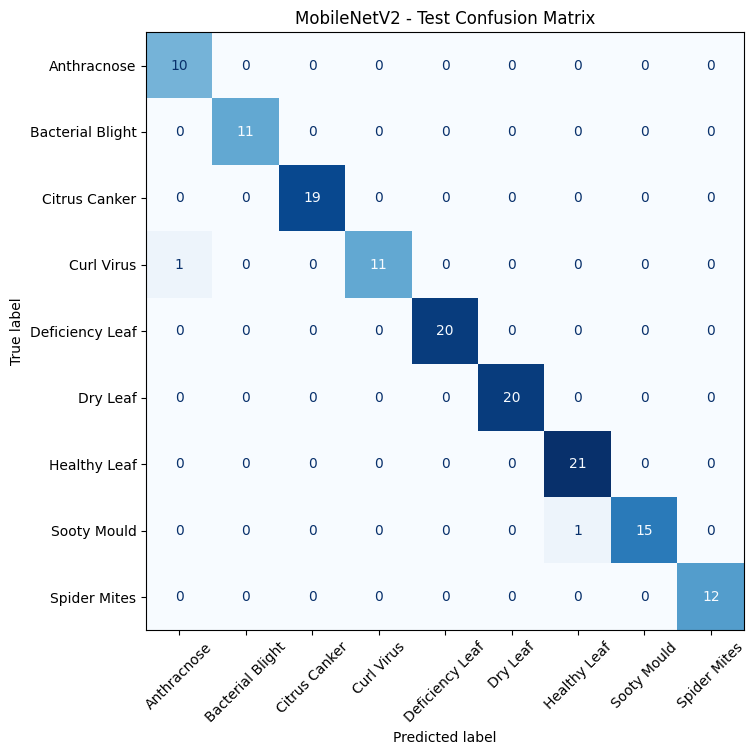

In [ ]:

import os
import gc
import math
import random
import warnings
import logging
from pathlib import Path
from contextlib import nullcontext

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"

warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import InterpolationMode


from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# ============================================================
# Configuration
# ============================================================

TRAIN_PATH = Path("/kaggle/working/papaya_leaf_train_augmented")
VAL_PATH = Path("/kaggle/working/papaya_leaf_split/validation")
TEST_PATH = Path("/kaggle/working/papaya_leaf_split/test")

OUTPUT_DIR = Path("/kaggle/working/papaya_mobilenetv2_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, CHECKPOINT_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "mobilenet_v2"
MODEL_SAVE_PATH = CHECKPOINT_DIR / "best_mobilenetv2.pth"

INPUT_SIZE = 224
EPOCHS = 30
PATIENCE = 5

BATCH_SIZE = 16
BACKBONE_LR = 3e-5
HEAD_LR = 2e-4
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.30

LABEL_SMOOTHING = 0.05
FOCAL_GAMMA = 1.5
WARMUP_EPOCHS = 3
USE_CLASS_WEIGHTS = True

SEED = 42
NUM_WORKERS = min(4, os.cpu_count() or 2)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"


# ============================================================
# Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


seed_everything(SEED)


# ============================================================
# Dataset checks
# ============================================================

for path in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Dataset path does not exist: {path}")

train_reference = datasets.ImageFolder(TRAIN_PATH)
val_reference = datasets.ImageFolder(VAL_PATH)
test_reference = datasets.ImageFolder(TEST_PATH)

CLASS_NAMES = train_reference.classes
NUM_CLASSES = len(CLASS_NAMES)

if NUM_CLASSES < 2:
    raise ValueError("At least two training classes are required.")

if val_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Validation classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nValidation: {val_reference.classes}"
    )

if test_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Test classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nTest: {test_reference.classes}"
    )

del train_reference, val_reference, test_reference


# ============================================================
# Pretrained CNN creation and classifier replacement
# ============================================================

def create_pretrained_model():
    try:
        weights = models.MobileNet_V2_Weights.DEFAULT
        current_model = models.mobilenet_v2(
            weights=weights,
            progress=False,
        )
    except AttributeError:
        current_model = models.mobilenet_v2(
            pretrained=True,
            progress=False,
        )

    in_features = current_model.classifier[1].in_features
    current_model.classifier = nn.Sequential(
        nn.Dropout(p=DROPOUT_RATE),
        nn.Linear(in_features, NUM_CLASSES),
    )

    return current_model, current_model.classifier


model, head_module = create_pretrained_model()
model = model.to(DEVICE)


# ============================================================
# ImageNet normalization and transforms
# ============================================================

MODEL_MEAN = (0.485, 0.456, 0.406)
MODEL_STD = (0.229, 0.224, 0.225)
INTERPOLATION = InterpolationMode.BILINEAR

train_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=8,
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])

evaluation_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])


# ============================================================
# Datasets and loaders
# ============================================================

train_dataset = datasets.ImageFolder(
    TRAIN_PATH,
    transform=train_transform,
)

val_dataset = datasets.ImageFolder(
    VAL_PATH,
    transform=evaluation_transform,
)

test_dataset = datasets.ImageFolder(
    TEST_PATH,
    transform=evaluation_transform,
)

if train_dataset.class_to_idx != val_dataset.class_to_idx:
    raise ValueError("Train and validation class mappings are different.")

if train_dataset.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test class mappings are different.")

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": AMP_ENABLED,
    "persistent_workers": NUM_WORKERS > 0,
    "worker_init_fn": seed_worker,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=False,
    generator=loader_generator,
    **loader_common,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)


# ============================================================
# Class weights
# ============================================================

def get_class_weights(dataset):
    if not USE_CLASS_WEIGHTS:
        return None

    counts = np.bincount(
        dataset.targets,
        minlength=NUM_CLASSES,
    ).astype(np.float32)

    if np.any(counts == 0):
        raise ValueError(f"Empty class detected. Counts: {counts.tolist()}")

    weights = len(dataset) / (NUM_CLASSES * counts)
    weights = weights / weights.mean()

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=DEVICE,
    )


class_weights = get_class_weights(train_dataset)


# ============================================================
# Focal loss with label smoothing
# ============================================================

class FocalLoss(nn.Module):
    def __init__(
        self,
        gamma=1.5,
        label_smoothing=0.05,
        weight=None,
    ):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing

        if weight is None:
            self.register_buffer("weight", None)
        else:
            self.register_buffer("weight", weight)

    def forward(self, logits, targets):
        cross_entropy = F.cross_entropy(
            logits,
            targets,
            weight=self.weight,
            label_smoothing=self.label_smoothing,
            reduction="none",
        )

        target_probability = F.softmax(
            logits,
            dim=1,
        ).gather(
            1,
            targets.unsqueeze(1),
        ).squeeze(1)

        focal_factor = (1.0 - target_probability).pow(self.gamma)
        return (focal_factor * cross_entropy).mean()


criterion = FocalLoss(
    gamma=FOCAL_GAMMA,
    label_smoothing=LABEL_SMOOTHING,
    weight=class_weights,
)


# ============================================================
# Backbone and classification-head parameter groups
# ============================================================

def build_optimizer(current_model, current_head):
    head_parameter_ids = {
        id(parameter)
        for parameter in current_head.parameters()
        if parameter.requires_grad
    }

    backbone_parameters = []
    head_parameters = []

    for parameter in current_model.parameters():
        if not parameter.requires_grad:
            continue

        if id(parameter) in head_parameter_ids:
            head_parameters.append(parameter)
        else:
            backbone_parameters.append(parameter)

    parameter_groups = []

    if backbone_parameters:
        parameter_groups.append({
            "params": backbone_parameters,
            "lr": BACKBONE_LR,
            "initial_lr": BACKBONE_LR,
        })

    if head_parameters:
        parameter_groups.append({
            "params": head_parameters,
            "lr": HEAD_LR,
            "initial_lr": HEAD_LR,
        })

    if not parameter_groups:
        raise ValueError("No trainable model parameters were found.")

    return torch.optim.AdamW(
        parameter_groups,
        weight_decay=WEIGHT_DECAY,
    )


optimizer = build_optimizer(model, head_module)


# ============================================================
# Warm-up plus cosine schedule
# ============================================================

def update_learning_rate(current_optimizer, epoch):
    if epoch < WARMUP_EPOCHS:
        factor = (epoch + 1) / max(1, WARMUP_EPOCHS)
    else:
        progress = (
            (epoch - WARMUP_EPOCHS)
            / max(1, EPOCHS - WARMUP_EPOCHS - 1)
        )
        factor = 0.5 * (1.0 + math.cos(math.pi * progress))

    for group in current_optimizer.param_groups:
        group["lr"] = group["initial_lr"] * factor


# ============================================================
# AMP helpers
# ============================================================

def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )
    return nullcontext()


try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED,
    )


# ============================================================
# Model-output helper
# ============================================================

def get_logits(output):
    if isinstance(output, torch.Tensor):
        return output

    if isinstance(output, (tuple, list)):
        tensor_outputs = [
            item for item in output
            if isinstance(item, torch.Tensor)
        ]

        if not tensor_outputs:
            raise TypeError("No tensor found in model output.")

        return torch.stack(tensor_outputs, dim=0).mean(dim=0)

    if isinstance(output, dict):
        for key in ["logits", "pred", "output"]:
            if key in output and isinstance(output[key], torch.Tensor):
                return output[key]

    raise TypeError(f"Unsupported model output type: {type(output)}")


# ============================================================
# Silent validation
# ============================================================

@torch.inference_mode()
def validation_accuracy(current_model, loader):
    current_model.eval()

    correct = 0
    total = 0

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    return correct / max(1, total)


# ============================================================
# Silent training with early stopping
# ============================================================

best_val_accuracy = -1.0
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    update_learning_rate(optimizer, epoch)
    model.train()

    for images, targets in train_loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = get_logits(model(images))
            loss = criterion(logits, targets)

        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss detected.")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        scaler.step(optimizer)
        scaler.update()

    current_val_accuracy = validation_accuracy(
        model,
        val_loader,
    )

    if current_val_accuracy > best_val_accuracy + 1e-8:
        best_val_accuracy = current_val_accuracy
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "class_to_idx": train_dataset.class_to_idx,
                "model_name": MODEL_NAME,
                "input_size": INPUT_SIZE,
            },
            MODEL_SAVE_PATH,
        )
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break


# ============================================================
# Load best checkpoint
# ============================================================

try:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
        weights_only=True,
    )
except TypeError:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
    )

model.load_state_dict(checkpoint["model_state_dict"])


# ============================================================
# Test evaluation
# ============================================================

@torch.inference_mode()
def test_predictions(current_model, loader):
    current_model.eval()

    all_targets = []
    all_predictions = []

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions.tolist())
        all_targets.extend(targets.numpy().tolist())

    return np.asarray(all_targets), np.asarray(all_predictions)


y_true, y_pred = test_predictions(model, test_loader)

test_accuracy = accuracy_score(y_true, y_pred)

matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)


# ============================================================
# Save final results silently
# ============================================================

pd.DataFrame(
    matrix,
    index=CLASS_NAMES,
    columns=CLASS_NAMES,
).to_csv(
    TABLE_DIR / "mobilenetv2_confusion_matrix.csv"
)

pd.DataFrame([{
    "model": MODEL_NAME,
    "test_accuracy": test_accuracy,
    "test_accuracy_percent": test_accuracy * 100,
}]).to_csv(
    TABLE_DIR / "mobilenetv2_test_accuracy.csv",
    index=False,
)

figure_size = max(7.0, NUM_CLASSES * 0.85)

fig, ax = plt.subplots(
    figsize=(figure_size, figure_size)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("MobileNetV2 - Test Confusion Matrix")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

fig.savefig(
    PLOT_DIR / "mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)


# ============================================================
# Print only requested test results
# ============================================================

print(f"Model: {MODEL_NAME}")
print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(matrix)

plt.show()


# ============================================================
# Cleanup
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

RESNET101

Model: resnet101
Best Validation Accuracy: 100.00%
Test Accuracy: 99.29%
Confusion Matrix:
[[10  0  0  0  0  0  0  0  0]
 [ 0 11  0  0  0  0  0  0  0]
 [ 0  0 19  0  0  0  0  0  0]
 [ 0  0  0 12  0  0  0  0  0]
 [ 0  0  0  0 20  0  0  0  0]
 [ 0  0  0  0  0 20  0  0  0]
 [ 0  0  0  0  0  0 21  0  0]
 [ 0  0  0  0  0  0  1 15  0]
 [ 0  0  0  0  0  0  0  0 12]]


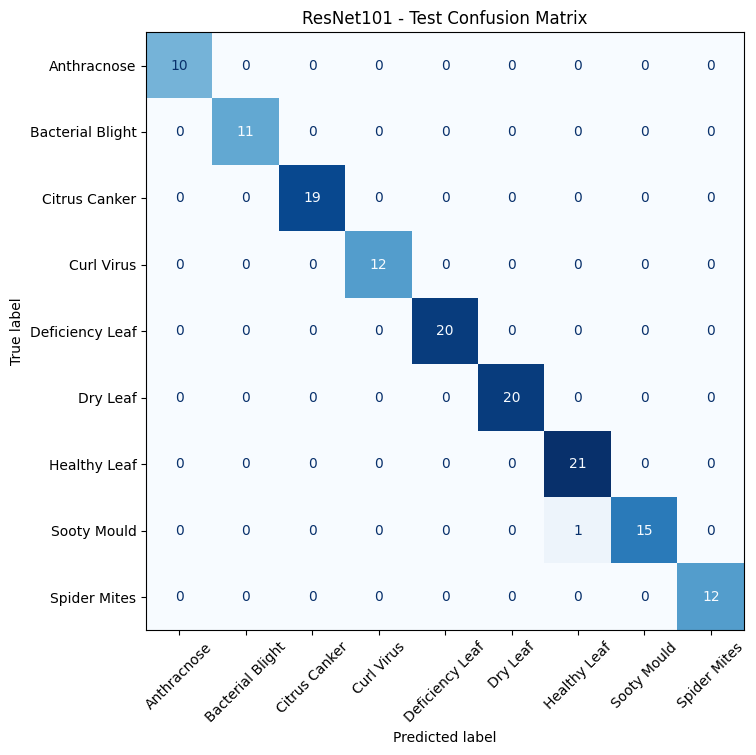

In [ ]:

import os
import gc
import math
import random
import warnings
import logging
from pathlib import Path
from contextlib import nullcontext

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"

warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import InterpolationMode


from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# ============================================================
# Configuration
# ============================================================

TRAIN_PATH = Path("/kaggle/working/papaya_leaf_train_augmented")
VAL_PATH = Path("/kaggle/working/papaya_leaf_split/validation")
TEST_PATH = Path("/kaggle/working/papaya_leaf_split/test")

OUTPUT_DIR = Path("/kaggle/working/papaya_resnet101_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, CHECKPOINT_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "resnet101"
MODEL_SAVE_PATH = CHECKPOINT_DIR / "best_resnet101.pth"

INPUT_SIZE = 224
EPOCHS = 30
PATIENCE = 5

BATCH_SIZE = 16
BACKBONE_LR = 3e-5
HEAD_LR = 2e-4
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.30

LABEL_SMOOTHING = 0.05
FOCAL_GAMMA = 1.5
WARMUP_EPOCHS = 3
USE_CLASS_WEIGHTS = True

SEED = 42
NUM_WORKERS = min(4, os.cpu_count() or 2)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"


# ============================================================
# Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


seed_everything(SEED)


# ============================================================
# Dataset checks
# ============================================================

for path in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Dataset path does not exist: {path}")

train_reference = datasets.ImageFolder(TRAIN_PATH)
val_reference = datasets.ImageFolder(VAL_PATH)
test_reference = datasets.ImageFolder(TEST_PATH)

CLASS_NAMES = train_reference.classes
NUM_CLASSES = len(CLASS_NAMES)

if NUM_CLASSES < 2:
    raise ValueError("At least two training classes are required.")

if val_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Validation classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nValidation: {val_reference.classes}"
    )

if test_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Test classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nTest: {test_reference.classes}"
    )

del train_reference, val_reference, test_reference


# ============================================================
# Pretrained CNN creation and classifier replacement
# ============================================================

def create_pretrained_model():
    try:
        weights = models.ResNet101_Weights.DEFAULT
        current_model = models.resnet101(
            weights=weights,
            progress=False,
        )
    except AttributeError:
        current_model = models.resnet101(
            pretrained=True,
            progress=False,
        )

    in_features = current_model.fc.in_features
    current_model.fc = nn.Sequential(
        nn.Dropout(p=DROPOUT_RATE),
        nn.Linear(in_features, NUM_CLASSES),
    )

    return current_model, current_model.fc


model, head_module = create_pretrained_model()
model = model.to(DEVICE)


# ============================================================
# ImageNet normalization and transforms
# ============================================================

MODEL_MEAN = (0.485, 0.456, 0.406)
MODEL_STD = (0.229, 0.224, 0.225)
INTERPOLATION = InterpolationMode.BILINEAR

train_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=8,
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])

evaluation_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])


# ============================================================
# Datasets and loaders
# ============================================================

train_dataset = datasets.ImageFolder(
    TRAIN_PATH,
    transform=train_transform,
)

val_dataset = datasets.ImageFolder(
    VAL_PATH,
    transform=evaluation_transform,
)

test_dataset = datasets.ImageFolder(
    TEST_PATH,
    transform=evaluation_transform,
)

if train_dataset.class_to_idx != val_dataset.class_to_idx:
    raise ValueError("Train and validation class mappings are different.")

if train_dataset.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test class mappings are different.")

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": AMP_ENABLED,
    "persistent_workers": NUM_WORKERS > 0,
    "worker_init_fn": seed_worker,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=False,
    generator=loader_generator,
    **loader_common,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)


# ============================================================
# Class weights
# ============================================================

def get_class_weights(dataset):
    if not USE_CLASS_WEIGHTS:
        return None

    counts = np.bincount(
        dataset.targets,
        minlength=NUM_CLASSES,
    ).astype(np.float32)

    if np.any(counts == 0):
        raise ValueError(f"Empty class detected. Counts: {counts.tolist()}")

    weights = len(dataset) / (NUM_CLASSES * counts)
    weights = weights / weights.mean()

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=DEVICE,
    )


class_weights = get_class_weights(train_dataset)


# ============================================================
# Focal loss with label smoothing
# ============================================================

class FocalLoss(nn.Module):
    def __init__(
        self,
        gamma=1.5,
        label_smoothing=0.05,
        weight=None,
    ):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing

        if weight is None:
            self.register_buffer("weight", None)
        else:
            self.register_buffer("weight", weight)

    def forward(self, logits, targets):
        cross_entropy = F.cross_entropy(
            logits,
            targets,
            weight=self.weight,
            label_smoothing=self.label_smoothing,
            reduction="none",
        )

        target_probability = F.softmax(
            logits,
            dim=1,
        ).gather(
            1,
            targets.unsqueeze(1),
        ).squeeze(1)

        focal_factor = (1.0 - target_probability).pow(self.gamma)
        return (focal_factor * cross_entropy).mean()


criterion = FocalLoss(
    gamma=FOCAL_GAMMA,
    label_smoothing=LABEL_SMOOTHING,
    weight=class_weights,
)


# ============================================================
# Backbone and classification-head parameter groups
# ============================================================

def build_optimizer(current_model, current_head):
    head_parameter_ids = {
        id(parameter)
        for parameter in current_head.parameters()
        if parameter.requires_grad
    }

    backbone_parameters = []
    head_parameters = []

    for parameter in current_model.parameters():
        if not parameter.requires_grad:
            continue

        if id(parameter) in head_parameter_ids:
            head_parameters.append(parameter)
        else:
            backbone_parameters.append(parameter)

    parameter_groups = []

    if backbone_parameters:
        parameter_groups.append({
            "params": backbone_parameters,
            "lr": BACKBONE_LR,
            "initial_lr": BACKBONE_LR,
        })

    if head_parameters:
        parameter_groups.append({
            "params": head_parameters,
            "lr": HEAD_LR,
            "initial_lr": HEAD_LR,
        })

    if not parameter_groups:
        raise ValueError("No trainable model parameters were found.")

    return torch.optim.AdamW(
        parameter_groups,
        weight_decay=WEIGHT_DECAY,
    )


optimizer = build_optimizer(model, head_module)


# ============================================================
# Warm-up plus cosine schedule
# ============================================================

def update_learning_rate(current_optimizer, epoch):
    if epoch < WARMUP_EPOCHS:
        factor = (epoch + 1) / max(1, WARMUP_EPOCHS)
    else:
        progress = (
            (epoch - WARMUP_EPOCHS)
            / max(1, EPOCHS - WARMUP_EPOCHS - 1)
        )
        factor = 0.5 * (1.0 + math.cos(math.pi * progress))

    for group in current_optimizer.param_groups:
        group["lr"] = group["initial_lr"] * factor


# ============================================================
# AMP helpers
# ============================================================

def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )
    return nullcontext()


try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED,
    )


# ============================================================
# Model-output helper
# ============================================================

def get_logits(output):
    if isinstance(output, torch.Tensor):
        return output

    if isinstance(output, (tuple, list)):
        tensor_outputs = [
            item for item in output
            if isinstance(item, torch.Tensor)
        ]

        if not tensor_outputs:
            raise TypeError("No tensor found in model output.")

        return torch.stack(tensor_outputs, dim=0).mean(dim=0)

    if isinstance(output, dict):
        for key in ["logits", "pred", "output"]:
            if key in output and isinstance(output[key], torch.Tensor):
                return output[key]

    raise TypeError(f"Unsupported model output type: {type(output)}")


# ============================================================
# Silent validation
# ============================================================

@torch.inference_mode()
def validation_accuracy(current_model, loader):
    current_model.eval()

    correct = 0
    total = 0

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    return correct / max(1, total)


# ============================================================
# Silent training with early stopping
# ============================================================

best_val_accuracy = -1.0
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    update_learning_rate(optimizer, epoch)
    model.train()

    for images, targets in train_loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = get_logits(model(images))
            loss = criterion(logits, targets)

        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss detected.")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        scaler.step(optimizer)
        scaler.update()

    current_val_accuracy = validation_accuracy(
        model,
        val_loader,
    )

    if current_val_accuracy > best_val_accuracy + 1e-8:
        best_val_accuracy = current_val_accuracy
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "class_to_idx": train_dataset.class_to_idx,
                "model_name": MODEL_NAME,
                "input_size": INPUT_SIZE,
            },
            MODEL_SAVE_PATH,
        )
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break


# ============================================================
# Load best checkpoint
# ============================================================

try:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
        weights_only=True,
    )
except TypeError:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
    )

model.load_state_dict(checkpoint["model_state_dict"])


# ============================================================
# Test evaluation
# ============================================================

@torch.inference_mode()
def test_predictions(current_model, loader):
    current_model.eval()

    all_targets = []
    all_predictions = []

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions.tolist())
        all_targets.extend(targets.numpy().tolist())

    return np.asarray(all_targets), np.asarray(all_predictions)


y_true, y_pred = test_predictions(model, test_loader)

test_accuracy = accuracy_score(y_true, y_pred)

matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)


# ============================================================
# Save final results silently
# ============================================================

pd.DataFrame(
    matrix,
    index=CLASS_NAMES,
    columns=CLASS_NAMES,
).to_csv(
    TABLE_DIR / "resnet101_confusion_matrix.csv"
)

pd.DataFrame([{
    "model": MODEL_NAME,
    "test_accuracy": test_accuracy,
    "test_accuracy_percent": test_accuracy * 100,
}]).to_csv(
    TABLE_DIR / "resnet101_test_accuracy.csv",
    index=False,
)

figure_size = max(7.0, NUM_CLASSES * 0.85)

fig, ax = plt.subplots(
    figsize=(figure_size, figure_size)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("ResNet101 - Test Confusion Matrix")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

fig.savefig(
    PLOT_DIR / "resnet101_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)


# ============================================================
# Print only requested test results
# ============================================================

print(f"Model: {MODEL_NAME}")
print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(matrix)

plt.show()


# ============================================================
# Cleanup
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

VGG19

Model: vgg19
Best Validation Accuracy: 99.24%
Test Accuracy: 96.45%
Confusion Matrix:
[[10  0  0  0  0  0  0  0  0]
 [ 0 11  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  3  0  0  0]
 [ 1  0  0 11  0  0  0  0  0]
 [ 0  0  0  0 20  0  0  0  0]
 [ 0  0  0  0  0 20  0  0  0]
 [ 0  0  0  0  0  0 21  0  0]
 [ 0  0  0  0  0  0  1 15  0]
 [ 0  0  0  0  0  0  0  0 12]]


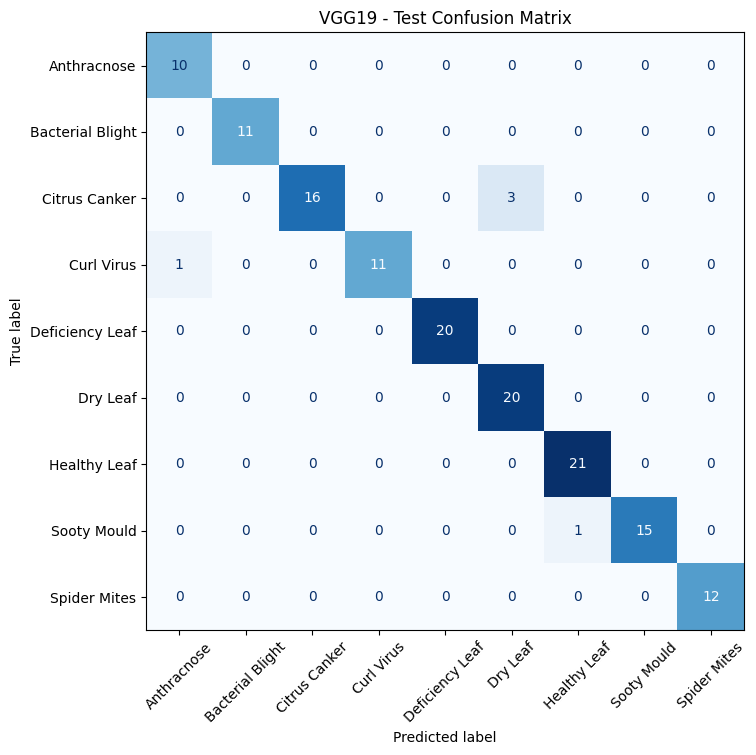

In [ ]:

import os
import gc
import math
import random
import warnings
import logging
from pathlib import Path
from contextlib import nullcontext

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"

warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import InterpolationMode


from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# ============================================================
# Configuration
# ============================================================

TRAIN_PATH = Path("/kaggle/working/papaya_leaf_train_augmented")
VAL_PATH = Path("/kaggle/working/papaya_leaf_split/validation")
TEST_PATH = Path("/kaggle/working/papaya_leaf_split/test")

OUTPUT_DIR = Path("/kaggle/working/papaya_vgg19_outputs")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, CHECKPOINT_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "vgg19"
MODEL_SAVE_PATH = CHECKPOINT_DIR / "best_vgg19.pth"

INPUT_SIZE = 224
EPOCHS = 30
PATIENCE = 5

BATCH_SIZE = 16
BACKBONE_LR = 3e-5
HEAD_LR = 2e-4
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.30

LABEL_SMOOTHING = 0.05
FOCAL_GAMMA = 1.5
WARMUP_EPOCHS = 3
USE_CLASS_WEIGHTS = True

SEED = 42
NUM_WORKERS = min(4, os.cpu_count() or 2)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"


# ============================================================
# Reproducibility
# ============================================================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


seed_everything(SEED)


# ============================================================
# Dataset checks
# ============================================================

for path in [TRAIN_PATH, VAL_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Dataset path does not exist: {path}")

train_reference = datasets.ImageFolder(TRAIN_PATH)
val_reference = datasets.ImageFolder(VAL_PATH)
test_reference = datasets.ImageFolder(TEST_PATH)

CLASS_NAMES = train_reference.classes
NUM_CLASSES = len(CLASS_NAMES)

if NUM_CLASSES < 2:
    raise ValueError("At least two training classes are required.")

if val_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Validation classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nValidation: {val_reference.classes}"
    )

if test_reference.classes != CLASS_NAMES:
    raise ValueError(
        f"Test classes do not match training classes.\n"
        f"Train: {CLASS_NAMES}\nTest: {test_reference.classes}"
    )

del train_reference, val_reference, test_reference


# ============================================================
# Pretrained CNN creation and classifier replacement
# ============================================================

def create_pretrained_model():
    try:
        weights = models.VGG19_Weights.DEFAULT
        current_model = models.vgg19(
            weights=weights,
            progress=False,
        )
    except AttributeError:
        current_model = models.vgg19(
            pretrained=True,
            progress=False,
        )

    for layer in current_model.classifier:
        if isinstance(layer, nn.Dropout):
            layer.p = DROPOUT_RATE

    in_features = current_model.classifier[6].in_features
    current_model.classifier[6] = nn.Linear(
        in_features,
        NUM_CLASSES,
    )

    return current_model, current_model.classifier[6]


model, head_module = create_pretrained_model()
model = model.to(DEVICE)


# ============================================================
# ImageNet normalization and transforms
# ============================================================

MODEL_MEAN = (0.485, 0.456, 0.406)
MODEL_STD = (0.229, 0.224, 0.225)
INTERPOLATION = InterpolationMode.BILINEAR

train_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=8,
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])

evaluation_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=INTERPOLATION,
    ),
    transforms.ToTensor(),
    transforms.Normalize(MODEL_MEAN, MODEL_STD),
])


# ============================================================
# Datasets and loaders
# ============================================================

train_dataset = datasets.ImageFolder(
    TRAIN_PATH,
    transform=train_transform,
)

val_dataset = datasets.ImageFolder(
    VAL_PATH,
    transform=evaluation_transform,
)

test_dataset = datasets.ImageFolder(
    TEST_PATH,
    transform=evaluation_transform,
)

if train_dataset.class_to_idx != val_dataset.class_to_idx:
    raise ValueError("Train and validation class mappings are different.")

if train_dataset.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test class mappings are different.")

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader_common = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": AMP_ENABLED,
    "persistent_workers": NUM_WORKERS > 0,
    "worker_init_fn": seed_worker,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    drop_last=False,
    generator=loader_generator,
    **loader_common,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    drop_last=False,
    **loader_common,
)


# ============================================================
# Class weights
# ============================================================

def get_class_weights(dataset):
    if not USE_CLASS_WEIGHTS:
        return None

    counts = np.bincount(
        dataset.targets,
        minlength=NUM_CLASSES,
    ).astype(np.float32)

    if np.any(counts == 0):
        raise ValueError(f"Empty class detected. Counts: {counts.tolist()}")

    weights = len(dataset) / (NUM_CLASSES * counts)
    weights = weights / weights.mean()

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=DEVICE,
    )


class_weights = get_class_weights(train_dataset)


# ============================================================
# Focal loss with label smoothing
# ============================================================

class FocalLoss(nn.Module):
    def __init__(
        self,
        gamma=1.5,
        label_smoothing=0.05,
        weight=None,
    ):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing

        if weight is None:
            self.register_buffer("weight", None)
        else:
            self.register_buffer("weight", weight)

    def forward(self, logits, targets):
        cross_entropy = F.cross_entropy(
            logits,
            targets,
            weight=self.weight,
            label_smoothing=self.label_smoothing,
            reduction="none",
        )

        target_probability = F.softmax(
            logits,
            dim=1,
        ).gather(
            1,
            targets.unsqueeze(1),
        ).squeeze(1)

        focal_factor = (1.0 - target_probability).pow(self.gamma)
        return (focal_factor * cross_entropy).mean()


criterion = FocalLoss(
    gamma=FOCAL_GAMMA,
    label_smoothing=LABEL_SMOOTHING,
    weight=class_weights,
)


# ============================================================
# Backbone and classification-head parameter groups
# ============================================================

def build_optimizer(current_model, current_head):
    head_parameter_ids = {
        id(parameter)
        for parameter in current_head.parameters()
        if parameter.requires_grad
    }

    backbone_parameters = []
    head_parameters = []

    for parameter in current_model.parameters():
        if not parameter.requires_grad:
            continue

        if id(parameter) in head_parameter_ids:
            head_parameters.append(parameter)
        else:
            backbone_parameters.append(parameter)

    parameter_groups = []

    if backbone_parameters:
        parameter_groups.append({
            "params": backbone_parameters,
            "lr": BACKBONE_LR,
            "initial_lr": BACKBONE_LR,
        })

    if head_parameters:
        parameter_groups.append({
            "params": head_parameters,
            "lr": HEAD_LR,
            "initial_lr": HEAD_LR,
        })

    if not parameter_groups:
        raise ValueError("No trainable model parameters were found.")

    return torch.optim.AdamW(
        parameter_groups,
        weight_decay=WEIGHT_DECAY,
    )


optimizer = build_optimizer(model, head_module)


# ============================================================
# Warm-up plus cosine schedule
# ============================================================

def update_learning_rate(current_optimizer, epoch):
    if epoch < WARMUP_EPOCHS:
        factor = (epoch + 1) / max(1, WARMUP_EPOCHS)
    else:
        progress = (
            (epoch - WARMUP_EPOCHS)
            / max(1, EPOCHS - WARMUP_EPOCHS - 1)
        )
        factor = 0.5 * (1.0 + math.cos(math.pi * progress))

    for group in current_optimizer.param_groups:
        group["lr"] = group["initial_lr"] * factor


# ============================================================
# AMP helpers
# ============================================================

def autocast_context():
    if AMP_ENABLED:
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )
    return nullcontext()


try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP_ENABLED,
    )
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP_ENABLED,
    )


# ============================================================
# Model-output helper
# ============================================================

def get_logits(output):
    if isinstance(output, torch.Tensor):
        return output

    if isinstance(output, (tuple, list)):
        tensor_outputs = [
            item for item in output
            if isinstance(item, torch.Tensor)
        ]

        if not tensor_outputs:
            raise TypeError("No tensor found in model output.")

        return torch.stack(tensor_outputs, dim=0).mean(dim=0)

    if isinstance(output, dict):
        for key in ["logits", "pred", "output"]:
            if key in output and isinstance(output[key], torch.Tensor):
                return output[key]

    raise TypeError(f"Unsupported model output type: {type(output)}")


# ============================================================
# Silent validation
# ============================================================

@torch.inference_mode()
def validation_accuracy(current_model, loader):
    current_model.eval()

    correct = 0
    total = 0

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1)
        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    return correct / max(1, total)


# ============================================================
# Silent training with early stopping
# ============================================================

best_val_accuracy = -1.0
epochs_without_improvement = 0

for epoch in range(EPOCHS):
    update_learning_rate(optimizer, epoch)
    model.train()

    for images, targets in train_loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = get_logits(model(images))
            loss = criterion(logits, targets)

        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite training loss detected.")

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        scaler.step(optimizer)
        scaler.update()

    current_val_accuracy = validation_accuracy(
        model,
        val_loader,
    )

    if current_val_accuracy > best_val_accuracy + 1e-8:
        best_val_accuracy = current_val_accuracy
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_names": CLASS_NAMES,
                "class_to_idx": train_dataset.class_to_idx,
                "model_name": MODEL_NAME,
                "input_size": INPUT_SIZE,
            },
            MODEL_SAVE_PATH,
        )
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            break


# ============================================================
# Load best checkpoint
# ============================================================

try:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
        weights_only=True,
    )
except TypeError:
    checkpoint = torch.load(
        MODEL_SAVE_PATH,
        map_location=DEVICE,
    )

model.load_state_dict(checkpoint["model_state_dict"])


# ============================================================
# Test evaluation
# ============================================================

@torch.inference_mode()
def test_predictions(current_model, loader):
    current_model.eval()

    all_targets = []
    all_predictions = []

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=AMP_ENABLED,
        )

        with autocast_context():
            logits = get_logits(current_model(images))

        predictions = logits.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions.tolist())
        all_targets.extend(targets.numpy().tolist())

    return np.asarray(all_targets), np.asarray(all_predictions)


y_true, y_pred = test_predictions(model, test_loader)

test_accuracy = accuracy_score(y_true, y_pred)

matrix = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
)


# ============================================================
# Save final results silently
# ============================================================

pd.DataFrame(
    matrix,
    index=CLASS_NAMES,
    columns=CLASS_NAMES,
).to_csv(
    TABLE_DIR / "vgg19_confusion_matrix.csv"
)

pd.DataFrame([{
    "model": MODEL_NAME,
    "test_accuracy": test_accuracy,
    "test_accuracy_percent": test_accuracy * 100,
}]).to_csv(
    TABLE_DIR / "vgg19_test_accuracy.csv",
    index=False,
)

figure_size = max(7.0, NUM_CLASSES * 0.85)

fig, ax = plt.subplots(
    figsize=(figure_size, figure_size)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
)

ax.set_title("VGG19 - Test Confusion Matrix")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

fig.savefig(
    PLOT_DIR / "vgg19_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)


# ============================================================
# Print only requested test results
# ============================================================

print(f"Model: {MODEL_NAME}")
print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Confusion Matrix:")
print(matrix)

plt.show()


# ============================================================
# Cleanup
# ============================================================

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()